# ScoutLens V2 — ML-Based Football Player Valuation & Undervalued Talent Discovery

**Goal:** Identify undervalued football players by predicting their market value from performance statistics and comparing predictions against actual market values. Special focus on talent in non-elite leagues (Tier 2/3).

**Pipeline overview:**
1. Setup & data loading
2. Active-player filter (age-aware minute thresholds)
3. Feature engineering (per-90 stats, league tier, transfer history, performance trend)
4. Target preparation & leakage cleanup
5. Model competition (XGBoost vs LightGBM vs RandomForest, 5-fold CV)
6. Position-based KMeans clustering with elbow validation
7. Value gap analysis & tier-weighted Top 30 recommendation
8. Visualizations & summary

**Target metric:** R² ≥ 0.55 on log(market_value). V1 baseline was 0.047.

**Reproducibility:** All randomness seeded with `SEED = 42`.


## Stage 1 — Setup & Data Loading

Install dependencies, import libraries, locate the 6 input CSVs, and run a sanity check on shapes and missing values.


In [1]:
# Install ML dependencies (already present in most Colab images, kept for portability)
!pip install -q xgboost lightgbm shap 2>&1 | tail -3


In [2]:
# === Core imports & global configuration ===
import os
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Global seed for reproducibility
SEED = 42
np.random.seed(SEED)

# Detect runtime environment
try:
    from google.colab import files as colab_files  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print(f"Environment: {'Google Colab' if IN_COLAB else 'Local'}")
print(f"Seed: {SEED}")


Environment: Google Colab
Seed: 42


In [3]:
# === Resolve data directory & load all six CSVs ===

REQUIRED_FILES = [
    "players.csv",
    "appearances.csv",
    "clubs.csv",
    "competitions.csv",
    "player_valuations.csv",
    "transfers.csv",
]

# Candidate locations, searched in order. The first directory that contains
# every required file wins. This makes the notebook work in Colab (/content),
# in a local data/ folder, or in the current directory.
CANDIDATE_DIRS = [Path("/content"), Path("/content/data"), Path("./data"), Path(".")]

DATA_DIR = None
for candidate in CANDIDATE_DIRS:
    if candidate.exists() and all((candidate / f).exists() for f in REQUIRED_FILES):
        DATA_DIR = candidate
        break

if DATA_DIR is None:
    msg = (
        f"Could not find all six CSVs in any of: {[str(c) for c in CANDIDATE_DIRS]}\n"
        f"Required files: {REQUIRED_FILES}\n"
        "Upload the CSVs to /content (Colab) or ./data (local) and rerun this cell."
    )
    raise FileNotFoundError(msg)

print(f"Data directory: {DATA_DIR.resolve()}\n")

# Load with low_memory=False to suppress dtype-inference warnings on mixed columns.
players       = pd.read_csv(DATA_DIR / "players.csv",            low_memory=False)
appearances   = pd.read_csv(DATA_DIR / "appearances.csv",        low_memory=False)
clubs         = pd.read_csv(DATA_DIR / "clubs.csv",              low_memory=False)
competitions  = pd.read_csv(DATA_DIR / "competitions.csv",       low_memory=False)
valuations    = pd.read_csv(DATA_DIR / "player_valuations.csv",  low_memory=False)
transfers     = pd.read_csv(DATA_DIR / "transfers.csv",          low_memory=False)

# Parse date columns up front (later stages depend on these being datetimes).
appearances["date"]        = pd.to_datetime(appearances["date"],        errors="coerce")
valuations["date"]         = pd.to_datetime(valuations["date"],         errors="coerce")
transfers["transfer_date"] = pd.to_datetime(transfers["transfer_date"], errors="coerce")
players["date_of_birth"]   = pd.to_datetime(players["date_of_birth"],   errors="coerce")

print("All six datasets loaded successfully.")


Data directory: /content

All six datasets loaded successfully.


In [4]:
# === Sanity check: shape + missing-value summary ===

datasets = {
    "players":      players,
    "appearances":  appearances,
    "clubs":        clubs,
    "competitions": competitions,
    "valuations":   valuations,
    "transfers":    transfers,
}

summary_rows = []
for name, df in datasets.items():
    summary_rows.append({
        "dataset":    name,
        "rows":       f"{len(df):,}",
        "columns":    df.shape[1],
        "memory_mb":  round(df.memory_usage(deep=True).sum() / 1e6, 1),
        "total_nans": f"{df.isna().sum().sum():,}",
    })

print("Dataset overview:")
print(pd.DataFrame(summary_rows).to_string(index=False))

# Per-column NaN rate for the primary table (players.csv)
print("\nNaN rate in players.csv (top 10 most-missing columns):")
nan_rates = (players.isna().mean() * 100).round(1).sort_values(ascending=False)
print(nan_rates.head(10).to_string())

# Quick note on what these NaN rates imply (handled in later stages):
#   - international_caps / international_goals: ~63% NaN  -> will be filled with 0
#     (no national-team appearance means 0 caps, not unknown).
#   - market_value_in_eur: ~34% NaN -> these rows are excluded in Stage 2.
#   - agent_name, contract_expiration_date: not used as features, ignore.
print("\nStage 1 complete.")


Dataset overview:
     dataset      rows  columns  memory_mb total_nans
     players    47,701       26       54.1    203,489
 appearances 1,885,688       13      491.0          2
       clubs       796       17        0.5      1,598
competitions        67       11        0.0         42
  valuations   507,815        6       75.1     22,599
   transfers    40,208       10       11.7     30,236

NaN rate in players.csv (top 10 most-missing columns):
current_national_team_id       94.9
international_caps             63.1
international_goals            63.1
agent_name                     46.2
contract_expiration_date       34.3
highest_market_value_in_eur    33.9
market_value_in_eur            33.9
country_of_birth               10.8
foot                           10.7
city_of_birth                  10.3

Stage 1 complete.


## Stage 2 — Active Player Filter

We need to keep only players who are *currently active*, not retired or long-inactive. The challenge: `appearances.csv` only covers top/mid-tier leagues, so players in very small leagues are absent regardless of activity. Within the covered leagues, we apply four conditions:

**Conditions (all must hold):**
1. `last_season >= 2024` — Transfermarkt-side activity flag.
2. `current_club_id` is not null — must belong to a club.
3. Played at least the age-adjusted minute threshold in the last 24 months.
4. `market_value_in_eur` is present and positive — target variable required.

**Age-adjusted minute thresholds** (kept lenient for young players — the project's stated goal is finding hidden talent, which is often young):

| Age range | Minimum minutes (last 24 months) |
|-----------|----------------------------------|
| < 21      | 90 (≈ 1 full match)              |
| 21–30     | 180 (≈ 2 matches)                |
| 30+       | 360 (≈ 4 matches)                |

A 19-year-old who just broke into the first team is preserved. A 32-year-old who barely played for two seasons is filtered out.

**Reference date** is the most recent appearance in the dataset (a proxy for "today" given the static snapshot).

In [5]:
# === Reference date + age calculation ===
REFERENCE_DATE = appearances["date"].max()
WINDOW_DAYS    = 730                                # 24 months
WINDOW_START   = REFERENCE_DATE - pd.Timedelta(days=WINDOW_DAYS)

print(f"Reference date (latest appearance in dataset): {REFERENCE_DATE.date()}")
print(f"Activity window starts:                        {WINDOW_START.date()}")

# Age at reference date
players["age"] = ((REFERENCE_DATE - players["date_of_birth"]).dt.days / 365.25).round(1)

Reference date (latest appearance in dataset): 2026-05-24
Activity window starts:                        2024-05-24


In [6]:
# === Recent activity aggregation ===

# Minutes played in last 24 months (per player)
recent_app = appearances[appearances["date"] >= WINDOW_START]
mins_recent = (
    recent_app.groupby("player_id")["minutes_played"]
    .sum()
    .rename("minutes_recent")
)

# Most recent appearance date overall (useful for downstream "still playing?" check)
last_app = (
    appearances.groupby("player_id")["date"]
    .max()
    .rename("last_appearance_date")
)

players_full = (
    players
    .merge(mins_recent,  on="player_id", how="left")
    .merge(last_app,     on="player_id", how="left")
)
players_full["minutes_recent"] = players_full["minutes_recent"].fillna(0)
players_full["days_since_last_match"] = (
    REFERENCE_DATE - players_full["last_appearance_date"]
).dt.days

# Age-adjusted minute threshold
def minute_threshold(age: float) -> int:
    if pd.isna(age):
        return 180
    if age < 21:
        return 90
    if age < 30:
        return 180
    return 360

players_full["min_threshold"] = players_full["age"].apply(minute_threshold)

print(f"Players annotated with activity stats. Rows: {len(players_full):,}")

Players annotated with activity stats. Rows: 47,701


In [7]:
# === Apply active-player mask ===
active_mask = (
    (players_full["last_season"] >= 2024)
    & (players_full["current_club_id"].notna())
    & (players_full["minutes_recent"] >= players_full["min_threshold"])
    & (players_full["market_value_in_eur"].notna())
    & (players_full["market_value_in_eur"] > 0)
    & (players_full["age"].between(15, 45))
)
active = players_full[active_mask].copy().reset_index(drop=True)

# Drop-reason breakdown (overlapping counts — a row can fail multiple conditions)
drop_reasons = {
    "last_season < 2024":           (players_full["last_season"] < 2024).sum(),
    "no current club":              players_full["current_club_id"].isna().sum(),
    "insufficient recent minutes":  (players_full["minutes_recent"] < players_full["min_threshold"]).sum(),
    "market_value missing or 0":    (players_full["market_value_in_eur"].isna()
                                     | (players_full["market_value_in_eur"] == 0)).sum(),
    "age out of [15, 45]":          (~players_full["age"].between(15, 45)).sum(),
}

print(f"Before filter: {len(players_full):,}")
print(f"After  filter: {len(active):,}")
print(f"Retention:     {len(active)/len(players_full)*100:.1f}%\n")
print("Drop reasons (overlapping):")
for reason, n in drop_reasons.items():
    print(f"  {reason:<32s} {n:>7,}")

print("\nActive-set position distribution:")
print(active["position"].value_counts().to_string())

Before filter: 47,701
After  filter: 6,952
Retention:     14.6%

Drop reasons (overlapping):
  last_season < 2024                22,054
  no current club                        0
  insufficient recent minutes       39,091
  market_value missing or 0         16,194
  age out of [15, 45]                1,015

Active-set position distribution:
position
Defender      2384
Midfield      2001
Attack        1948
Goalkeeper     619


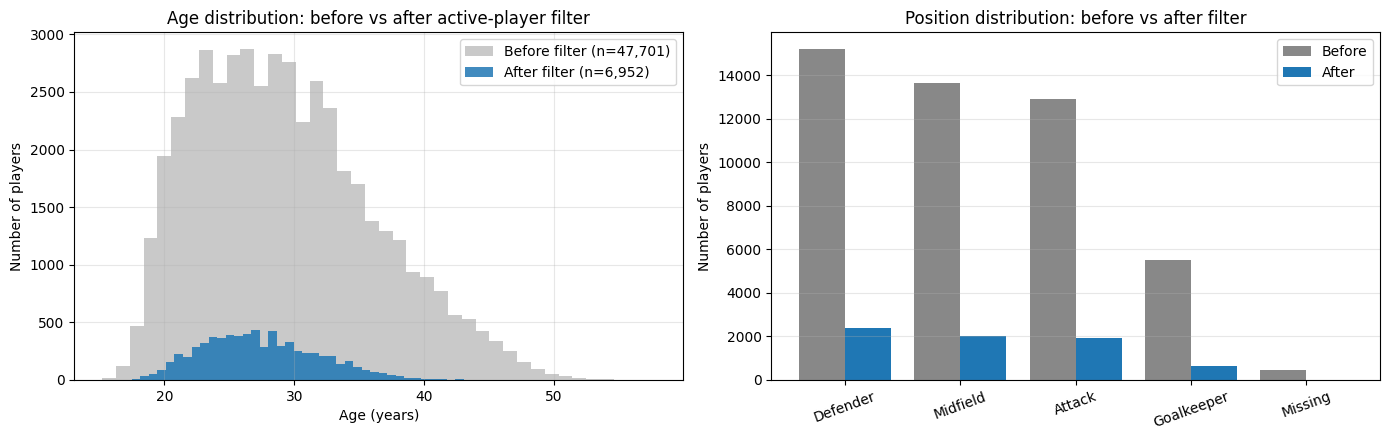

Saved: stage2_filter_diagnostic.png

Stage 2 complete. Active player set is in `active` (shape: (6952, 31) )


In [8]:
# === Visualize age and position distribution: before vs after filter ===

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Age histogram
axes[0].hist(players_full["age"].dropna(), bins=40, alpha=0.45,
             color="#888888", label=f"Before filter (n={len(players_full):,})")
axes[0].hist(active["age"].dropna(), bins=40, alpha=0.85,
             color="#1f77b4", label=f"After filter (n={len(active):,})")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Number of players")
axes[0].set_title("Age distribution: before vs after active-player filter")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Position bar chart
pos_before = players_full["position"].value_counts()
pos_after  = active["position"].value_counts().reindex(pos_before.index, fill_value=0)
x = np.arange(len(pos_before))
width = 0.4
axes[1].bar(x - width/2, pos_before.values, width, color="#888888", label="Before")
axes[1].bar(x + width/2, pos_after.values,  width, color="#1f77b4", label="After")
axes[1].set_xticks(x)
axes[1].set_xticklabels(pos_before.index, rotation=20)
axes[1].set_ylabel("Number of players")
axes[1].set_title("Position distribution: before vs after filter")
axes[1].legend()
axes[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig("stage2_filter_diagnostic.png", dpi=120, bbox_inches="tight")
plt.show()

print("Saved: stage2_filter_diagnostic.png")
print("\nStage 2 complete. Active player set is in `active` (shape:", active.shape, ")")

## Stage 3 — Feature Engineering

Build the feature matrix on the active player set. Five families of features:

1. **Per-90 performance metrics** (last 24 months): goals, assists, yellow cards, red cards, minutes per appearance — normalized per 90 minutes so a 200-minute starter is comparable to a 2000-minute regular.
2. **Performance trend**: ratio of goals+assists per 90 in the last 12 months vs the prior 12 months. Captures whether a player is improving or declining. Clipped to [0, 5] to suppress outliers.
3. **League tier** (from `competitions.csv`):
   - Tier 1: `GB1, ES1, IT1, L1, FR1` (Top-5)
   - Tier 2: `TR1, NL1, PO1, BE1`
   - Tier 3: everything else (including unknown / fallback)
4. **Transfer history** (from `transfers.csv`): max transfer fee ever paid for the player, and number of transfers. Note: this is a *noisy proxy* for value — only ~9% of transfers in the dataset have a non-zero fee. Importance will likely be low.
5. **Player attributes**: age, height (median-imputed), international caps/goals (NaN → 0), position one-hot, foot one-hot.

**Leakage cleanup:** The two columns `market_value_in_eur` and `highest_market_value_in_eur` are excluded from features. `market_value_in_eur` is the target; `highest_market_value_in_eur` is too tightly correlated with the target (same source) and would inflate R² without real predictive insight.

In [9]:
# === 1) Per-90 performance metrics from last 24 months ===
recent_active = recent_app[recent_app["player_id"].isin(active["player_id"])]

agg = (
    recent_active.groupby("player_id")
    .agg(
        total_minutes_24m  = ("minutes_played", "sum"),
        total_goals_24m    = ("goals",          "sum"),
        total_assists_24m  = ("assists",        "sum"),
        total_yellow_24m   = ("yellow_cards",   "sum"),
        total_red_24m      = ("red_cards",      "sum"),
        n_appearances_24m  = ("appearance_id",  "count"),
    )
    .reset_index()
)

def per_90(numerator, minutes):
    return np.where(minutes > 0, numerator * 90.0 / minutes, 0.0)

agg["goals_per_90"]   = per_90(agg["total_goals_24m"],   agg["total_minutes_24m"])
agg["assists_per_90"] = per_90(agg["total_assists_24m"], agg["total_minutes_24m"])
agg["yellow_per_90"]  = per_90(agg["total_yellow_24m"],  agg["total_minutes_24m"])
agg["red_per_90"]     = per_90(agg["total_red_24m"],     agg["total_minutes_24m"])
agg["mins_per_app"]   = np.where(
    agg["n_appearances_24m"] > 0,
    agg["total_minutes_24m"] / agg["n_appearances_24m"],
    0.0,
)

print(f"Per-90 aggregation done: {len(agg):,} players")

Per-90 aggregation done: 6,952 players


In [10]:
# === 2) Performance trend: last 12 mo vs prior 12 mo (goals+assists per 90 ratio) ===
SPLIT_DATE = REFERENCE_DATE - pd.Timedelta(days=365)

def ga_per_90(df):
    g = df.groupby("player_id").agg(
        g=("goals", "sum"),
        a=("assists", "sum"),
        m=("minutes_played", "sum"),
    )
    return np.where(g["m"] > 0, (g["g"] + g["a"]) * 90.0 / g["m"], 0.0), g.index

vals_recent, idx_recent = ga_per_90(recent_active[recent_active["date"] >= SPLIT_DATE])
vals_prior,  idx_prior  = ga_per_90(recent_active[recent_active["date"] <  SPLIT_DATE])
ga_recent = pd.Series(vals_recent, index=idx_recent, name="ga_p90_recent")
ga_prior  = pd.Series(vals_prior,  index=idx_prior,  name="ga_p90_prior")

trend = pd.concat([ga_recent, ga_prior], axis=1).fillna(0)
# Ratio recent/prior; when prior=0 (e.g. youth promoted within last year), use 1.0 = "no signal"
trend["performance_trend"] = np.where(
    trend["ga_p90_prior"] > 0,
    (trend["ga_p90_recent"] / trend["ga_p90_prior"]).clip(0, 5),
    1.0,
)
trend = trend.reset_index()[["player_id", "performance_trend"]]

print(f"Performance trend computed for {len(trend):,} players")
print(f"Trend distribution: mean={trend['performance_trend'].mean():.2f}, "
      f"median={trend['performance_trend'].median():.2f}")

Performance trend computed for 6,952 players
Trend distribution: mean=0.89, median=1.00


In [11]:
# === 3) League tier mapping ===
TIER1_LEAGUES = {"GB1", "ES1", "IT1", "L1", "FR1"}     # Top-5 European leagues
TIER2_LEAGUES = {"TR1", "NL1", "PO1", "BE1"}           # Strong second-tier European leagues

def assign_league_tier(competition_id):
    if pd.isna(competition_id):
        return 3                                       # fallback for missing league
    if competition_id in TIER1_LEAGUES:
        return 1
    if competition_id in TIER2_LEAGUES:
        return 2
    return 3

# === 4) Transfer-history features ===
transfers_with_fee = transfers.dropna(subset=["transfer_fee"]).copy()
transfer_agg = (
    transfers_with_fee.groupby("player_id")
    .agg(
        transfer_fee_paid = ("transfer_fee", "max"),
        n_transfers       = ("transfer_fee", "count"),
    )
    .reset_index()
)
print(f"Transfer history aggregated for {len(transfer_agg):,} players")
print(f"  Non-zero fee: {(transfer_agg['transfer_fee_paid']>0).sum():,}")
print(f"  Median (non-zero fee): €{transfer_agg.loc[transfer_agg['transfer_fee_paid']>0,'transfer_fee_paid'].median():,.0f}")
print("\nNote: transfer_fee_paid is a noisy proxy. ~91% of players in the active set")
print("will have transfer_fee_paid = 0 (free transfers or missing data).")

Transfer history aggregated for 4,423 players
  Non-zero fee: 1,680
  Median (non-zero fee): €1,200,000

Note: transfer_fee_paid is a noisy proxy. ~91% of players in the active set
will have transfer_fee_paid = 0 (free transfers or missing data).


In [12]:
# === Merge all feature blocks into a single dataframe `feat` ===
feat = (
    active
    .merge(agg,          on="player_id", how="left")
    .merge(trend,        on="player_id", how="left")
    .merge(transfer_agg, on="player_id", how="left")
)

# Fill missing values
fill_with_zero = [
    "total_minutes_24m", "total_goals_24m", "total_assists_24m",
    "total_yellow_24m",  "total_red_24m",   "n_appearances_24m",
    "goals_per_90", "assists_per_90", "yellow_per_90", "red_per_90", "mins_per_app",
    "transfer_fee_paid", "n_transfers",
    "international_caps", "international_goals",
]
for col in fill_with_zero:
    if col in feat.columns:
        feat[col] = feat[col].fillna(0)

# performance_trend default = 1.0 (no signal)
feat["performance_trend"] = feat["performance_trend"].fillna(1.0)

# League tier
feat["league_tier"] = feat["current_club_domestic_competition_id"].apply(assign_league_tier)

# Height impute with global median
feat["height_in_cm"] = feat["height_in_cm"].fillna(feat["height_in_cm"].median())

# Foot: missing -> 'unknown'
feat["foot"] = feat["foot"].fillna("unknown")

# === One-hot encoding for categorical fields ===
position_oh = pd.get_dummies(feat["position"], prefix="pos",  dtype=int)
foot_oh     = pd.get_dummies(feat["foot"],     prefix="foot", dtype=int)
feat = pd.concat([feat, position_oh, foot_oh], axis=1)

print(f"Feature dataframe shape: {feat.shape}")
print(f"One-hot columns added: {list(position_oh.columns) + list(foot_oh.columns)}")

Feature dataframe shape: (6952, 54)
One-hot columns added: ['pos_Attack', 'pos_Defender', 'pos_Goalkeeper', 'pos_Midfield', 'foot_both', 'foot_left', 'foot_right', 'foot_unknown']


In [13]:
# === Define final feature set + leakage assertion ===

NUMERIC_FEATURES = [
    "age", "height_in_cm",
    "international_caps", "international_goals",
    "total_minutes_24m", "n_appearances_24m", "mins_per_app",
    "goals_per_90", "assists_per_90", "yellow_per_90", "red_per_90",
    "performance_trend",
    "transfer_fee_paid", "n_transfers",
    "league_tier",
    "days_since_last_match",
]
CATEGORICAL_OH_FEATURES = list(position_oh.columns) + list(foot_oh.columns)
FEATURE_COLS = NUMERIC_FEATURES + CATEGORICAL_OH_FEATURES

# LEAKAGE GUARD: target and target-proxy columns must NOT be features
LEAKAGE_COLS = ["market_value_in_eur", "highest_market_value_in_eur"]
overlap = set(FEATURE_COLS) & set(LEAKAGE_COLS)
assert not overlap, f"LEAKAGE DETECTED: {overlap} present in FEATURE_COLS"

# Build X (features) and y (target, log-transformed)
X       = feat[FEATURE_COLS].copy()
y_raw   = feat["market_value_in_eur"].copy()
y_log   = np.log1p(y_raw)

# Final NaN guard on X
nan_cols = X.columns[X.isna().any()].tolist()
assert not nan_cols, f"NaN found in feature matrix: {nan_cols}"

print(f"Feature matrix X: {X.shape}")
print(f"  {len(NUMERIC_FEATURES)} numeric + {len(CATEGORICAL_OH_FEATURES)} one-hot = {len(FEATURE_COLS)} total")
print(f"Target y_log: mean={y_log.mean():.2f}, std={y_log.std():.2f}, range=[{y_log.min():.2f}, {y_log.max():.2f}]")
print(f"Target y_raw: median=€{y_raw.median():,.0f}, mean=€{y_raw.mean():,.0f}")
print("\nLeakage check passed. Stage 3 complete.")

Feature matrix X: (6952, 24)
  16 numeric + 8 one-hot = 24 total
Target y_log: mean=14.32, std=1.59, range=[10.13, 19.11]
Target y_raw: median=€1,500,000, mean=€5,810,309

Leakage check passed. Stage 3 complete.


## Stage 4+5 — Train/Test Split & Model Competition

**Stage 4** is the train/test split (80/20, random_state=42). **Stage 5** is a head-to-head between three gradient/tree ensembles using 5-fold cross-validation on the training set:

| Model         | Why include it                                                |
|---------------|---------------------------------------------------------------|
| RandomForest  | Robust baseline, low tuning sensitivity                       |
| XGBoost       | Stronger gradient boosting, usually wins on tabular           |
| LightGBM      | Fast histogram-based GBM, sometimes beats XGBoost             |

We pick the model with the highest 5-fold CV R², refit it on the full training set, and report performance on the held-out test set. We also produce three diagnostics: feature importance, SHAP summary, and a predicted-vs-actual scatter.

**Baseline reference:** V1 of this project achieved R² = 0.047 (formula-based, not a real model). Our target is R² ≥ 0.55 on log(market_value).

In [14]:
# === Stage 4: Train/test split ===
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y_log, test_size=0.2, random_state=SEED
)
print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")

Train: (5561, 24)
Test:  (1391, 24)


In [15]:
# === Stage 5a: Cross-validated model competition ===
import time
from sklearn.model_selection import KFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
import lightgbm as lgb

candidate_models = {
    "RandomForest": RandomForestRegressor(
        n_estimators=300, max_depth=15, min_samples_leaf=5,
        n_jobs=-1, random_state=SEED,
    ),
    "XGBoost": xgb.XGBRegressor(
        n_estimators=400, learning_rate=0.05, max_depth=6,
        subsample=0.85, colsample_bytree=0.85,
        random_state=SEED, n_jobs=-1, verbosity=0,
    ),
    "LightGBM": lgb.LGBMRegressor(
        n_estimators=400, learning_rate=0.05, max_depth=-1,
        num_leaves=63, subsample=0.85, colsample_bytree=0.85,
        random_state=SEED, n_jobs=-1, verbose=-1,
    ),
}

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_results = []
print(f"{'Model':<14s} {'R² (CV)':<22s} {'RMSE (CV)':<14s} {'Time':<8s}")
for name, model in candidate_models.items():
    t0 = time.time()
    cv_r2   = cross_val_score(model, X_train, y_train, cv=kf, scoring="r2", n_jobs=1)
    cv_rmse = -cross_val_score(model, X_train, y_train, cv=kf,
                                scoring="neg_root_mean_squared_error", n_jobs=1)
    elapsed = time.time() - t0
    cv_results.append({
        "model": name,
        "r2_cv_mean":   cv_r2.mean(),
        "r2_cv_std":    cv_r2.std(),
        "rmse_cv_mean": cv_rmse.mean(),
        "time_sec":     elapsed,
    })
    print(f"  {name:<12s}  {cv_r2.mean():.4f} ± {cv_r2.std():.4f}    "
          f"{cv_rmse.mean():.4f}      {elapsed:5.1f}s")

cv_results_df = pd.DataFrame(cv_results).sort_values("r2_cv_mean", ascending=False)
best_model_name = cv_results_df.iloc[0]["model"]
print(f"\nBest model: {best_model_name}")

Model          R² (CV)                RMSE (CV)      Time    
  RandomForest  0.6446 ± 0.0221    0.9471       95.1s
  XGBoost       0.6584 ± 0.0245    0.9284       15.4s
  LightGBM      0.6489 ± 0.0263    0.9411       11.5s

Best model: XGBoost


In [16]:
# === Stage 5b: Fit best model on full train + test-set evaluation ===
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

best_model = candidate_models[best_model_name]
best_model.fit(X_train, y_train)

pred_test_log = best_model.predict(X_test)
pred_test_eur = np.expm1(pred_test_log)
y_test_eur    = np.expm1(y_test)

test_r2       = r2_score(y_test, pred_test_log)
test_rmse_log = np.sqrt(mean_squared_error(y_test, pred_test_log))
test_mae_eur  = mean_absolute_error(y_test_eur, pred_test_eur)

print(f"Test set performance ({best_model_name}):")
print(f"  R² (log scale):        {test_r2:.4f}")
print(f"  RMSE (log scale):      {test_rmse_log:.4f}")
print(f"  MAE (EUR scale):       €{test_mae_eur:,.0f}")
print(f"  Test set median value: €{y_test_eur.median():,.0f}")
print(f"  V1 baseline R²:        0.0470")
print(f"  Improvement factor:    {test_r2 / 0.047:.1f}x")

# Predictions on the full active set (used downstream for value-gap analysis)
feat["predicted_log_value"] = best_model.predict(X)
feat["predicted_value_eur"] = np.expm1(feat["predicted_log_value"])

Test set performance (XGBoost):
  R² (log scale):        0.6766
  RMSE (log scale):      0.8954
  MAE (EUR scale):       €3,119,129
  Test set median value: €1,500,000
  V1 baseline R²:        0.0470
  Improvement factor:    14.4x


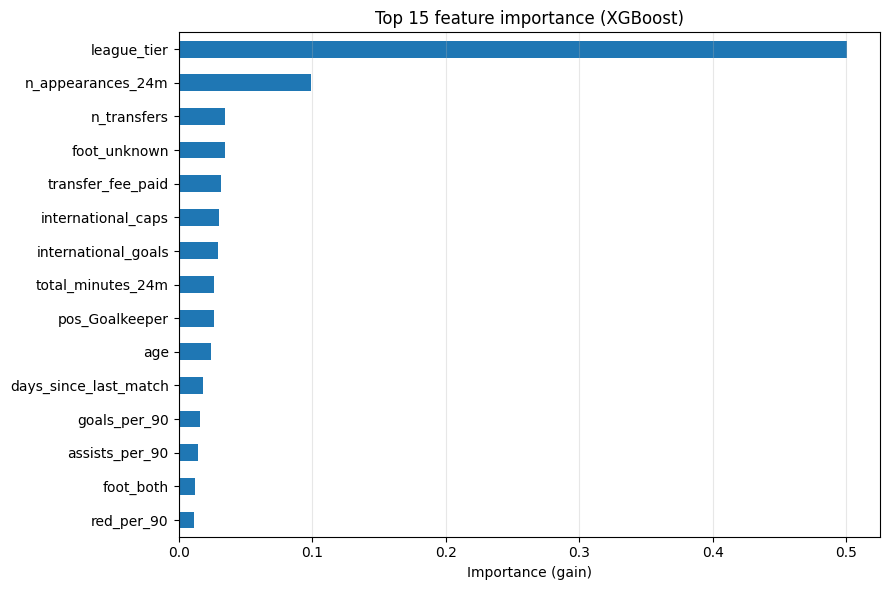

In [17]:
# === Stage 5c: Feature importance (built-in) ===
importance = pd.Series(best_model.feature_importances_, index=FEATURE_COLS)
importance = importance.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
importance.tail(15).plot(kind="barh", color="#1f77b4", ax=ax)
ax.set_title(f"Top 15 feature importance ({best_model_name})")
ax.set_xlabel("Importance (gain)")
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.savefig("stage5_feature_importance.png", dpi=120, bbox_inches="tight")
plt.show()

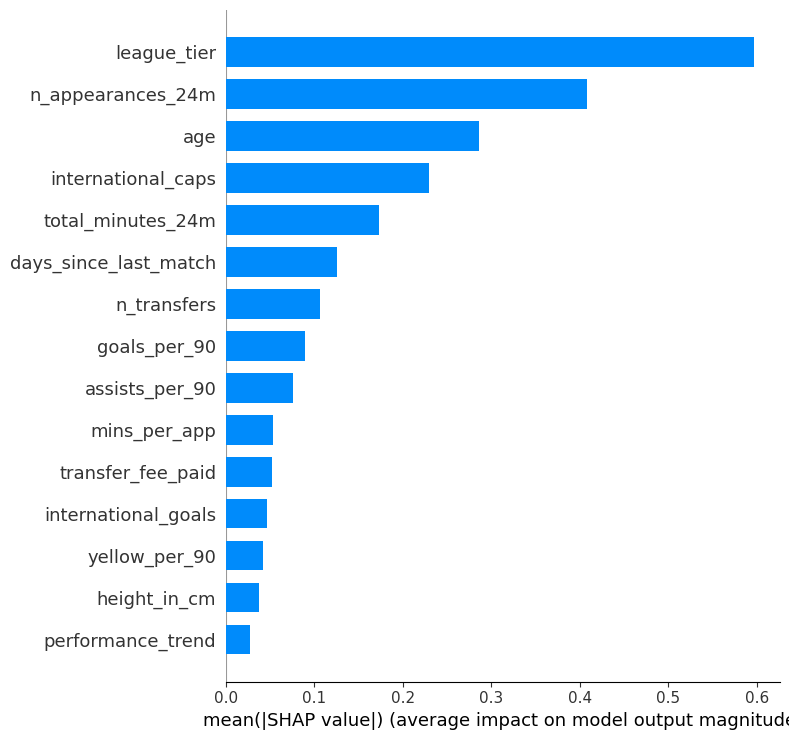

SHAP summary saved.


In [18]:
# === Stage 5d: SHAP summary (optional — skipped gracefully if SHAP unavailable) ===
try:
    import shap
    rng = np.random.RandomState(SEED)
    sample_idx = rng.choice(len(X), size=min(1000, len(X)), replace=False)
    explainer  = shap.TreeExplainer(best_model)
    shap_values = explainer.shap_values(X.iloc[sample_idx])

    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values, X.iloc[sample_idx], plot_type="bar",
                      show=False, max_display=15)
    plt.tight_layout()
    plt.savefig("stage5_shap_summary.png", dpi=120, bbox_inches="tight")
    plt.show()
    print("SHAP summary saved.")
except Exception as exc:
    print(f"SHAP unavailable, skipping. Reason: {exc}")

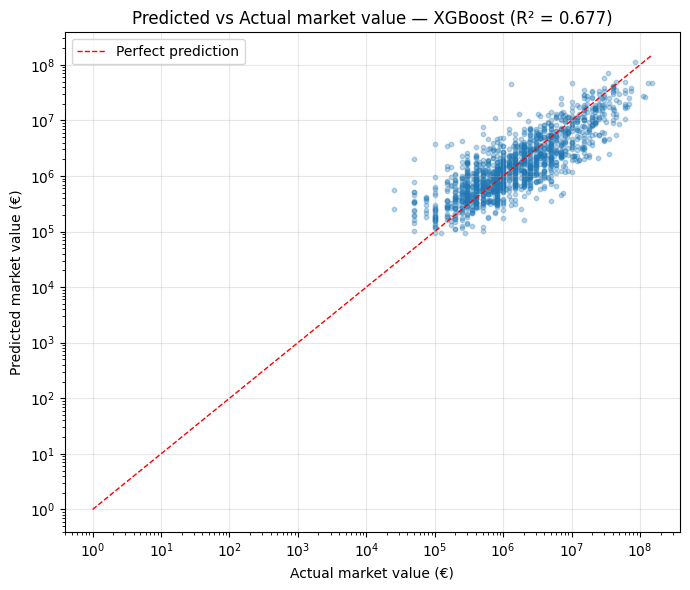


Stage 5 complete. Best model: XGBoost, Test R² = 0.6766


In [19]:
# === Stage 5e: Predicted vs Actual scatter (test set, log-log) ===
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test_eur, pred_test_eur, alpha=0.3, s=10, color="#1f77b4")
lim = max(y_test_eur.max(), pred_test_eur.max())
ax.plot([1, lim], [1, lim], color="red", linestyle="--", linewidth=1, label="Perfect prediction")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Actual market value (€)")
ax.set_ylabel("Predicted market value (€)")
ax.set_title(f"Predicted vs Actual market value — {best_model_name} (R² = {test_r2:.3f})")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("stage5_pred_vs_actual.png", dpi=120, bbox_inches="tight")
plt.show()

print(f"\nStage 5 complete. Best model: {best_model_name}, Test R² = {test_r2:.4f}")

## Stage 6 — Position-Based KMeans Clustering

V1's biggest clustering failure was a single global KMeans across all positions, which produced absurdly imbalanced clusters (1 player in one bucket, 17k in another). We fix this by clustering **separately within each position** so a striker is compared to other strikers, a defender to other defenders, etc.

**Clustering features** (intentionally *excluding* `market_value` and `league_tier`):
`age, height_in_cm, goals_per_90, assists_per_90, yellow_per_90, mins_per_app, n_appearances_24m, performance_trend, international_caps`

Excluding `league_tier` is deliberate: we want a Tier-3 prolific scorer to land in the same archetype as a Tier-1 prolific scorer — otherwise clustering just re-discovers the league hierarchy.

**Choosing k per position:**
1. Default `k = 4`.
2. If any cluster has < 2% of the position, step k down (avoids the V1 singleton-cluster bug).
3. Else, silhouette override: if a larger k yields silhouette > 1.15× the silhouette at chosen k, use it.

**Archetype names** are derived automatically from the cluster center: whichever feature deviates most from the position mean (in z-score terms) labels the archetype.

In [21]:
# === Stage 6a: Configuration + helper functions ===
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

CLUSTER_FEATURES = [
    "age", "height_in_cm",
    "goals_per_90", "assists_per_90", "yellow_per_90",
    "mins_per_app", "n_appearances_24m",
    "performance_trend", "international_caps",
]
POSITIONS = ["Attack", "Midfield", "Defender", "Goalkeeper"]
MIN_CLUSTER_SHARE = 0.02   # No cluster may be smaller than 2% of its position
K_RANGE = list(range(2, 9))

# Auto-archetype labeller: pick the most-deviating feature, name it accordingly
ARCHETYPE_LABELS = {
    "goals_per_90":       ("Prolific Scorer", "Low Output"),
    "assists_per_90":     ("Creator",         "Non-Creator"),
    "mins_per_app":       ("Regular Starter", "Bench/Sub"),
    "n_appearances_24m":  ("Workhorse",       "Rare Player"),
    "age":                ("Veteran",         "Young Prospect"),
    "height_in_cm":       ("Tall Profile",    "Compact Profile"),
    "yellow_per_90":      ("Aggressive",      "Calm"),
    "performance_trend":  ("Improving",       "Declining"),
    "international_caps": ("Capped Intl.",    "Uncapped"),
}

def name_archetype(centers_df, cluster_idx, position):
    centers_z = (centers_df - centers_df.mean()) / centers_df.std().replace(0, 1)
    z = centers_z.iloc[cluster_idx]
    top_feat = z.abs().idxmax()
    sign = "high" if z[top_feat] > 0 else "low"
    pos_label, neg_label = ARCHETYPE_LABELS.get(
        top_feat, (f"High {top_feat}", f"Low {top_feat}")
    )
    arch = pos_label if sign == "high" else neg_label
    return f"{position[:3]}_C{cluster_idx}_{arch}"

def choose_k(X_scaled, k_range=K_RANGE, min_share=MIN_CLUSTER_SHARE):
    inertias, silhouettes, valid_ks = [], [], []
    for k in k_range:
        km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
        labels = km.fit_predict(X_scaled)
        sizes = pd.Series(labels).value_counts()
        inertias.append(km.inertia_)
        silhouettes.append(silhouette_score(X_scaled, labels))
        if sizes.min() / len(labels) >= min_share:
            valid_ks.append(k)

    # Prefer k=4 if it's valid; otherwise fall back to the largest valid k
    if 4 in valid_ks:
        chosen = 4
    elif valid_ks:
        # If 4 fails, pick the largest valid k <= 4 (degrade gracefully)
        valid_below_4 = [k for k in valid_ks if k <= 4]
        chosen = max(valid_below_4) if valid_below_4 else min(valid_ks)
    else:
        chosen = 2

    # Silhouette override: only consider k > chosen (prefer richer clustering when justified)
    base_sil = silhouettes[k_range.index(chosen)]
    bigger_candidates = [
        (k, silhouettes[k_range.index(k)])
        for k in valid_ks if k > chosen and silhouettes[k_range.index(k)] > base_sil * 1.15
    ]
    if bigger_candidates:
        chosen = max(bigger_candidates, key=lambda x: x[1])[0]

    return chosen, inertias, silhouettes, valid_ks


Attack (n=1,948) — chosen k=4 (valid k values: [2, 3, 4, 5, 6, 7, 8])
  C0  n= 193 (  9.9%)  Att_C0_Capped Intl.
  C1  n= 727 ( 37.3%)  Att_C1_Improving
  C2  n= 725 ( 37.2%)  Att_C2_Compact Profile
  C3  n= 303 ( 15.6%)  Att_C3_Aggressive

Midfield (n=2,001) — chosen k=4 (valid k values: [2, 3, 4, 5, 6, 7, 8])
  C0  n= 347 ( 17.3%)  Mid_C0_Prolific Scorer
  C1  n= 842 ( 42.1%)  Mid_C1_Aggressive
  C2  n= 600 ( 30.0%)  Mid_C2_Improving
  C3  n= 212 ( 10.6%)  Mid_C3_Capped Intl.

Defender (n=2,384) — chosen k=4 (valid k values: [2, 3, 4, 5, 6, 7, 8])
  C0  n= 473 ( 19.8%)  Def_C0_Improving
  C1  n= 673 ( 28.2%)  Def_C1_Bench/Sub
  C2  n= 997 ( 41.8%)  Def_C2_Tall Profile
  C3  n= 241 ( 10.1%)  Def_C3_Capped Intl.

Goalkeeper (n=619) — chosen k=3 (valid k values: [2, 3])
  C0  n= 174 ( 28.1%)  Goa_C0_Calm
  C1  n=  32 (  5.2%)  Goa_C1_Declining
  C2  n= 413 ( 66.7%)  Goa_C2_Uncapped


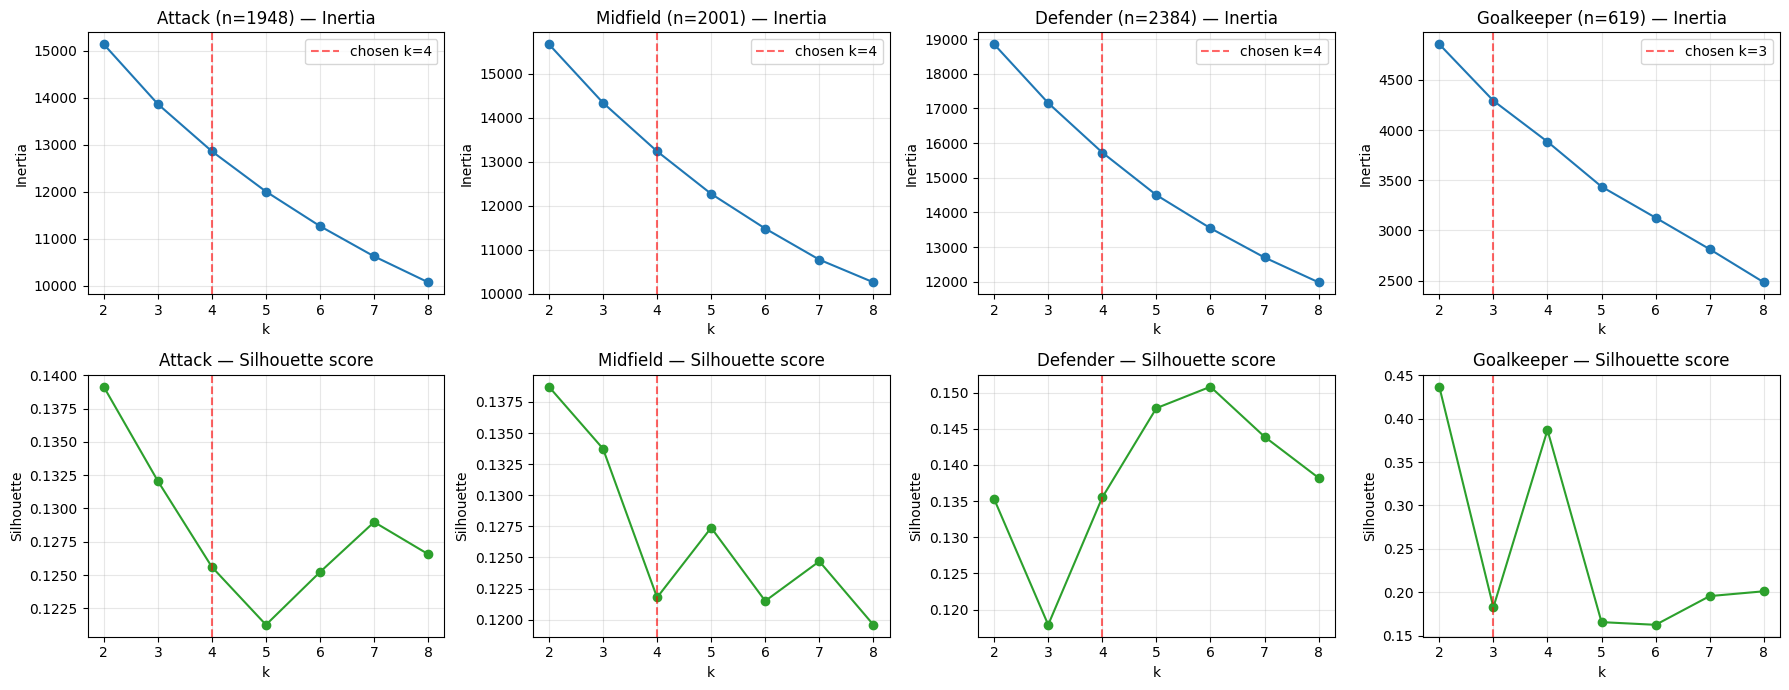

In [22]:
# === Stage 6b: Cluster each position separately + visualize ===
cluster_results = {}
fig, axes = plt.subplots(2, 4, figsize=(18, 7))

for col_idx, pos in enumerate(POSITIONS):
    sub = feat[feat["position"] == pos].copy()
    scaler = StandardScaler()
    X_pos = scaler.fit_transform(sub[CLUSTER_FEATURES])

    chosen_k, inertias, silhouettes, valid_ks = choose_k(X_pos)

    # Final clustering at chosen k
    final_km = KMeans(n_clusters=chosen_k, random_state=SEED, n_init=10)
    labels = final_km.fit_predict(X_pos)
    centers_unscaled = scaler.inverse_transform(final_km.cluster_centers_)
    centers_df = pd.DataFrame(centers_unscaled, columns=CLUSTER_FEATURES)

    cluster_names = {ci: name_archetype(centers_df, ci, pos) for ci in range(chosen_k)}
    sub["cluster_id"] = labels
    sub["archetype"]  = sub["cluster_id"].map(cluster_names)

    sizes = sub["cluster_id"].value_counts().sort_index()
    print(f"\n{pos} (n={len(sub):,}) — chosen k={chosen_k} (valid k values: {valid_ks})")
    for ci, sz in sizes.items():
        print(f"  C{ci}  n={sz:>4d} ({sz/len(sub)*100:5.1f}%)  {cluster_names[ci]}")

    cluster_results[pos] = sub[["player_id", "cluster_id", "archetype"]]

    # Diagnostic plots: inertia + silhouette per position
    axes[0, col_idx].plot(K_RANGE, inertias, "o-", color="#1f77b4")
    axes[0, col_idx].axvline(chosen_k, color="red", linestyle="--", alpha=0.6,
                              label=f"chosen k={chosen_k}")
    axes[0, col_idx].set_title(f"{pos} (n={len(sub)}) — Inertia")
    axes[0, col_idx].set_xlabel("k"); axes[0, col_idx].set_ylabel("Inertia")
    axes[0, col_idx].legend(); axes[0, col_idx].grid(alpha=0.3)

    axes[1, col_idx].plot(K_RANGE, silhouettes, "o-", color="#2ca02c")
    axes[1, col_idx].axvline(chosen_k, color="red", linestyle="--", alpha=0.6)
    axes[1, col_idx].set_title(f"{pos} — Silhouette score")
    axes[1, col_idx].set_xlabel("k"); axes[1, col_idx].set_ylabel("Silhouette")
    axes[1, col_idx].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("stage6_elbow_silhouette.png", dpi=120, bbox_inches="tight")
plt.show()

In [23]:
# === Stage 6c: Merge archetype labels back into the main feature dataframe ===
all_clusters = pd.concat(cluster_results.values(), ignore_index=True)
feat = feat.merge(all_clusters, on="player_id", how="left")

print(f"Total unique archetypes: {feat['archetype'].nunique()}")
print(f"Smallest archetype size: {feat['archetype'].value_counts().min()}")
print(f"\nArchetype distribution (sorted by size):")
print(feat["archetype"].value_counts().to_string())

print(f"\nStage 6 complete. Every player now has a `cluster_id` and `archetype`.")

Total unique archetypes: 15
Smallest archetype size: 32

Archetype distribution (sorted by size):
archetype
Def_C2_Tall Profile       997
Mid_C1_Aggressive         842
Att_C1_Improving          727
Att_C2_Compact Profile    725
Def_C1_Bench/Sub          673
Mid_C2_Improving          600
Def_C0_Improving          473
Goa_C2_Uncapped           413
Mid_C0_Prolific Scorer    347
Att_C3_Aggressive         303
Def_C3_Capped Intl.       241
Mid_C3_Capped Intl.       212
Att_C0_Capped Intl.       193
Goa_C0_Calm               174
Goa_C1_Declining           32

Stage 6 complete. Every player now has a `cluster_id` and `archetype`.


## Stage 7 — Value Gap Analysis & Top-30 Undervalued Recommendations

**The recommendation logic in three steps:**

**1. Define value gap on the log scale.** Since the model was trained on `log(market_value)`, the natural metric is
`value_gap_log = log(predicted) − log(actual)`. This is symmetric, outlier-resistant, and reads as "how many times off" — a log gap of 2.3 means the model thinks the player is worth ~10× their listed price.

**2. Compare within archetype.** A "20% undervalued striker" is much more interesting than a generic global ranking. For each archetype, we pick the top 25% by `value_gap_log` — these are the players the model thinks are most underpriced relative to peers with similar profiles.

**3. Apply a league-tier quota to surface non-elite leagues.** The project's stated goal is finding talent in less-popular leagues. To prevent the list from being dominated by Top-5 league players, we cap Tier-1 picks at 12 out of 30 (≥ 60% must be Tier 2/3).

**Eligibility filter:** `market_value_in_eur >= €100,000`. Below this floor, Transfermarkt values are often placeholders or stale, making the gap metric unreliable.

**Output:** `undervalued_players.json` — 30 records with full feature context for each pick, plus a metadata block.

In [24]:
# === Stage 7a: Compute value-gap metrics ===
feat["log_actual"]    = np.log1p(feat["market_value_in_eur"])
feat["log_predicted"] = feat["predicted_log_value"]
feat["value_gap_log"] = feat["log_predicted"] - feat["log_actual"]
feat["value_gap_eur"] = feat["predicted_value_eur"] - feat["market_value_in_eur"]
feat["value_gap_pct"] = (feat["value_gap_eur"] / feat["market_value_in_eur"]) * 100

# Eligibility filter — exclude very low market-value labels (likely noise/placeholders)
MIN_MARKET_VALUE = 100_000
eligible = feat[feat["market_value_in_eur"] >= MIN_MARKET_VALUE].copy()
print(f"Eligible pool (market_value >= €{MIN_MARKET_VALUE:,}): {len(eligible):,}")
print(f"Excluded (below floor): {len(feat) - len(eligible):,}")

Eligible pool (market_value >= €100,000): 6,824
Excluded (below floor): 128


In [25]:
# === Stage 7b: Archetype-relative ranking + tier quota ===
# Within each archetype, take the top 25% by log gap = "most undervalued for their type"
eligible["archetype_pct_rank"] = eligible.groupby("archetype")["value_gap_log"].rank(pct=True)
undervalued = eligible[eligible["archetype_pct_rank"] >= 0.75].copy()
undervalued = undervalued.sort_values("value_gap_log", ascending=False).reset_index(drop=True)

print(f"Undervalued candidates (top 25% of each archetype): {len(undervalued):,}")
print(f"  Tier 1 share: {(undervalued['league_tier']==1).mean()*100:.1f}%")
print(f"  Tier 2 share: {(undervalued['league_tier']==2).mean()*100:.1f}%")
print(f"  Tier 3 share: {(undervalued['league_tier']==3).mean()*100:.1f}%")

# Apply tier quota: max 12 Tier-1 picks in final Top 30
TOP_N    = 30
MAX_TIER1 = 12

selected = []
tier1_count = 0
for _, row in undervalued.iterrows():
    if len(selected) >= TOP_N:
        break
    if row["league_tier"] == 1 and tier1_count >= MAX_TIER1:
        continue
    selected.append(row)
    if row["league_tier"] == 1:
        tier1_count += 1

top30 = pd.DataFrame(selected).reset_index(drop=True)
tier_counts = top30["league_tier"].value_counts().to_dict()
print(f"\nFinal Top {TOP_N}: "
      f"Tier 1 = {tier_counts.get(1, 0)}, "
      f"Tier 2 = {tier_counts.get(2, 0)}, "
      f"Tier 3 = {tier_counts.get(3, 0)}")
print(f"Tier 2 + 3 share: {(top30['league_tier']>=2).mean()*100:.1f}% (project target: >= 60%)")

Undervalued candidates (top 25% of each archetype): 1,715
  Tier 1 share: 35.1%
  Tier 2 share: 25.2%
  Tier 3 share: 39.7%

Final Top 30: Tier 1 = 12, Tier 2 = 6, Tier 3 = 12
Tier 2 + 3 share: 60.0% (project target: >= 60%)


In [26]:
# === Stage 7c: Write undervalued_players.json + preview ===
records = []
for rank, r in top30.iterrows():
    records.append({
        "rank":                       int(rank + 1),
        "player_id":                  int(r["player_id"]),
        "name":                       str(r["name"]),
        "age":                        round(float(r["age"]), 1),
        "position":                   str(r["position"]),
        "sub_position":               str(r["sub_position"]) if pd.notna(r.get("sub_position")) else None,
        "current_club":               str(r["current_club_name"]) if pd.notna(r["current_club_name"]) else None,
        "league_id":                  str(r["current_club_domestic_competition_id"]) if pd.notna(r["current_club_domestic_competition_id"]) else None,
        "league_tier":                int(r["league_tier"]),
        "archetype":                  str(r["archetype"]),
        "current_market_value_eur":   round(float(r["market_value_in_eur"]), 0),
        "predicted_value_eur":        round(float(r["predicted_value_eur"]), 0),
        "value_gap_eur":              round(float(r["value_gap_eur"]), 0),
        "value_gap_log":              round(float(r["value_gap_log"]), 3),
        "value_gap_pct":              round(float(r["value_gap_pct"]), 1),
        "total_minutes_24m":          int(r["total_minutes_24m"]),
        "appearances_24m":            int(r["n_appearances_24m"]),
        "goals_per_90":               round(float(r["goals_per_90"]), 3),
        "assists_per_90":             round(float(r["assists_per_90"]), 3),
        "international_caps":         int(r["international_caps"]),
        "last_appearance_date":       r["last_appearance_date"].strftime("%Y-%m-%d") if pd.notna(r["last_appearance_date"]) else None,
        "days_since_last_match":      int(r["days_since_last_match"]) if pd.notna(r["days_since_last_match"]) else None,
    })

output_doc = {
    "metadata": {
        "reference_date":         REFERENCE_DATE.strftime("%Y-%m-%d"),
        "active_player_pool":     int(len(feat)),
        "eligible_pool":          int(len(eligible)),
        "undervalued_candidates": int(len(undervalued)),
        "model":                  best_model_name,
        "test_r2":                round(float(test_r2), 4),
        "top_n":                  TOP_N,
        "tier1_quota_max":        MAX_TIER1,
        "min_market_value_eur":   MIN_MARKET_VALUE,
        "sort_metric":            "value_gap_log (predicted_log − actual_log)",
        "tier_distribution":      {
            "tier_1": int((top30["league_tier"] == 1).sum()),
            "tier_2": int((top30["league_tier"] == 2).sum()),
            "tier_3": int((top30["league_tier"] == 3).sum()),
        },
    },
    "players": records,
}

with open("undervalued_players.json", "w", encoding="utf-8") as f:
    json.dump(output_doc, f, indent=2, ensure_ascii=False)

print(f"Wrote undervalued_players.json — {len(records)} records")

# Preview the top 10 picks in a readable table
preview = top30[[
    "name", "age", "position", "current_club_name", "league_tier", "archetype",
    "market_value_in_eur", "predicted_value_eur", "value_gap_log",
]].head(10).copy()
preview["market_value_in_eur"]  = preview["market_value_in_eur"].apply(
    lambda x: f"€{x/1e6:.2f}M" if x >= 1e6 else f"€{x/1e3:.0f}k")
preview["predicted_value_eur"]  = preview["predicted_value_eur"].apply(
    lambda x: f"€{x/1e6:.2f}M" if x >= 1e6 else f"€{x/1e3:.0f}k")
preview["value_gap_log"]        = preview["value_gap_log"].round(2)
print("\nTop 10 picks preview:")
print(preview.to_string(index=False))

print(f"\nStage 7 complete. JSON ready for downstream consumption.")

Wrote undervalued_players.json — 30 records

Top 10 picks preview:
              name  age position               current_club_name  league_tier              archetype market_value_in_eur predicted_value_eur  value_gap_log
   Yassin Belkhdim 24.3 Midfield Angers Sporting Club de l'Ouest            1       Mid_C2_Improving               €100k              €3.75M           3.63
       Ernest Poku 22.3   Attack     Bayer 04 Leverkusen Fußball            1       Att_C1_Improving              €1.30M             €46.13M           3.57
    Nicolò Bertola 23.2 Defender                  Udinese Calcio            1    Def_C2_Tall Profile               €150k              €3.47M           3.14
   Luca Marianucci 21.8 Defender                   Torino Calcio            1       Def_C1_Bench/Sub               €175k              €3.79M           3.08
Sindre Walle Egeli 19.9   Attack       Fodbold Club Nordsjælland            3 Att_C2_Compact Profile               €250k              €4.29M           2.

## Stage 8 — Final Visualizations & Pipeline Summary

Three required visualizations plus a pipeline summary table:

1. **Correlation heatmap** — How numeric features relate to each other and to market value. Spots leakage (none) and confirms which signals carry weight.
2. **Value gap distribution per position** — Distribution of `value_gap_log` per position. A symmetric distribution around 0 means the model has no systematic bias.
3. **Archetype distribution per position** — Cluster sizes for every position, confirming all archetypes are balanced (≥ 2% of their position).

Plus a final summary table covering all 8 pipeline stages and a head-to-head with V1.

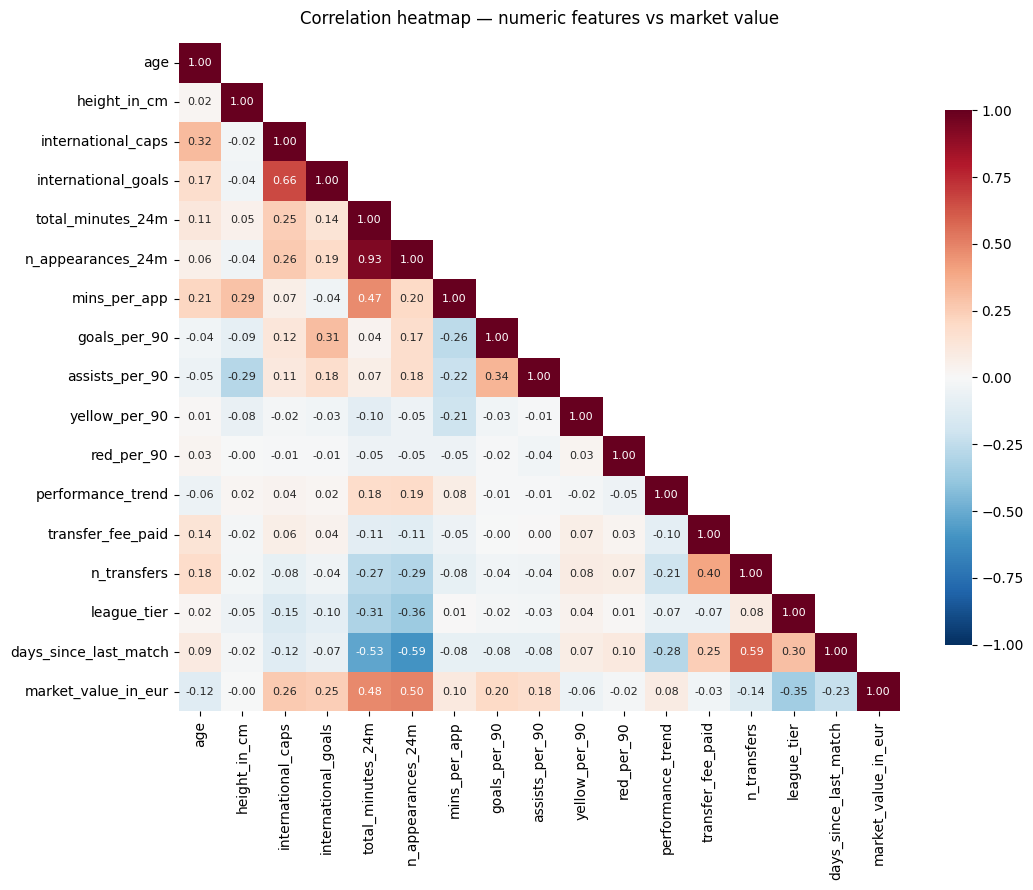

In [27]:
# === Viz 1: Correlation heatmap ===
corr_cols = NUMERIC_FEATURES + ["market_value_in_eur"]
corr = feat[corr_cols].corr()

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f",
    cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    square=False, cbar_kws={"shrink": 0.8},
    annot_kws={"size": 8}, ax=ax,
)
ax.set_title("Correlation heatmap — numeric features vs market value", pad=14)
plt.tight_layout()
plt.savefig("viz_correlation_heatmap.png", dpi=120, bbox_inches="tight")
plt.show()

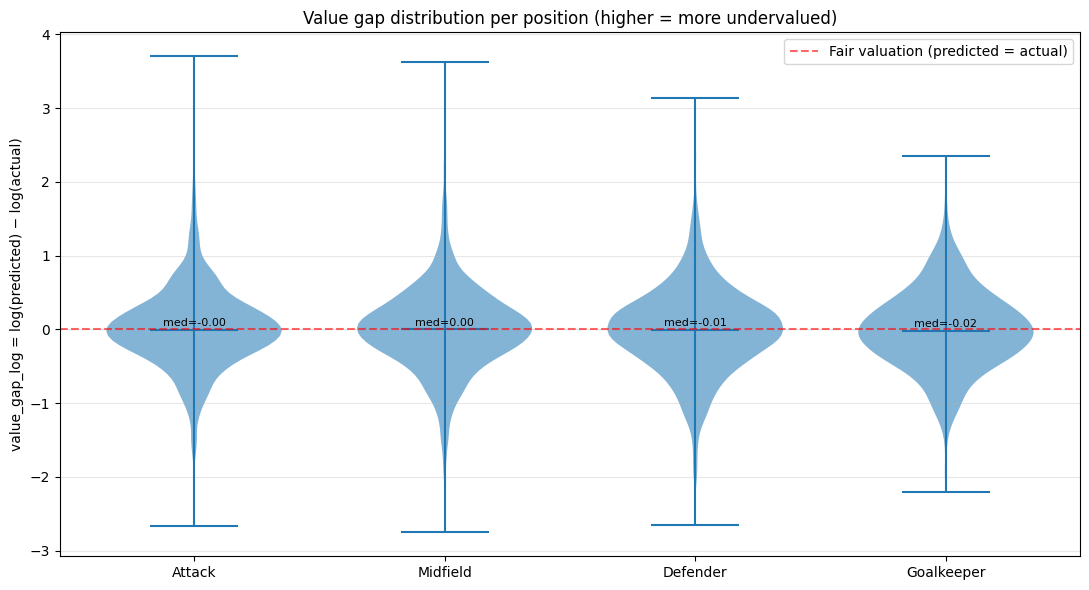

In [28]:
# === Viz 2: Value gap distribution per position (violin) ===
fig, ax = plt.subplots(figsize=(11, 6))
positions_plot = ["Attack", "Midfield", "Defender", "Goalkeeper"]
data_by_pos = [feat[feat["position"] == p]["value_gap_log"].dropna() for p in positions_plot]

parts = ax.violinplot(data_by_pos, showmedians=True, widths=0.7)
for pc in parts["bodies"]:
    pc.set_facecolor("#1f77b4")
    pc.set_alpha(0.55)

ax.axhline(0, color="red", linestyle="--", alpha=0.6,
           label="Fair valuation (predicted = actual)")
ax.set_xticks(range(1, len(positions_plot) + 1))
ax.set_xticklabels(positions_plot)
ax.set_ylabel("value_gap_log = log(predicted) − log(actual)")
ax.set_title("Value gap distribution per position (higher = more undervalued)")
ax.legend(loc="upper right")
ax.grid(alpha=0.3, axis="y")

for i, p in enumerate(positions_plot, 1):
    med = feat[feat["position"] == p]["value_gap_log"].median()
    ax.text(i, med + 0.05, f"med={med:.2f}", ha="center", fontsize=8)

plt.tight_layout()
plt.savefig("viz_value_gap_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

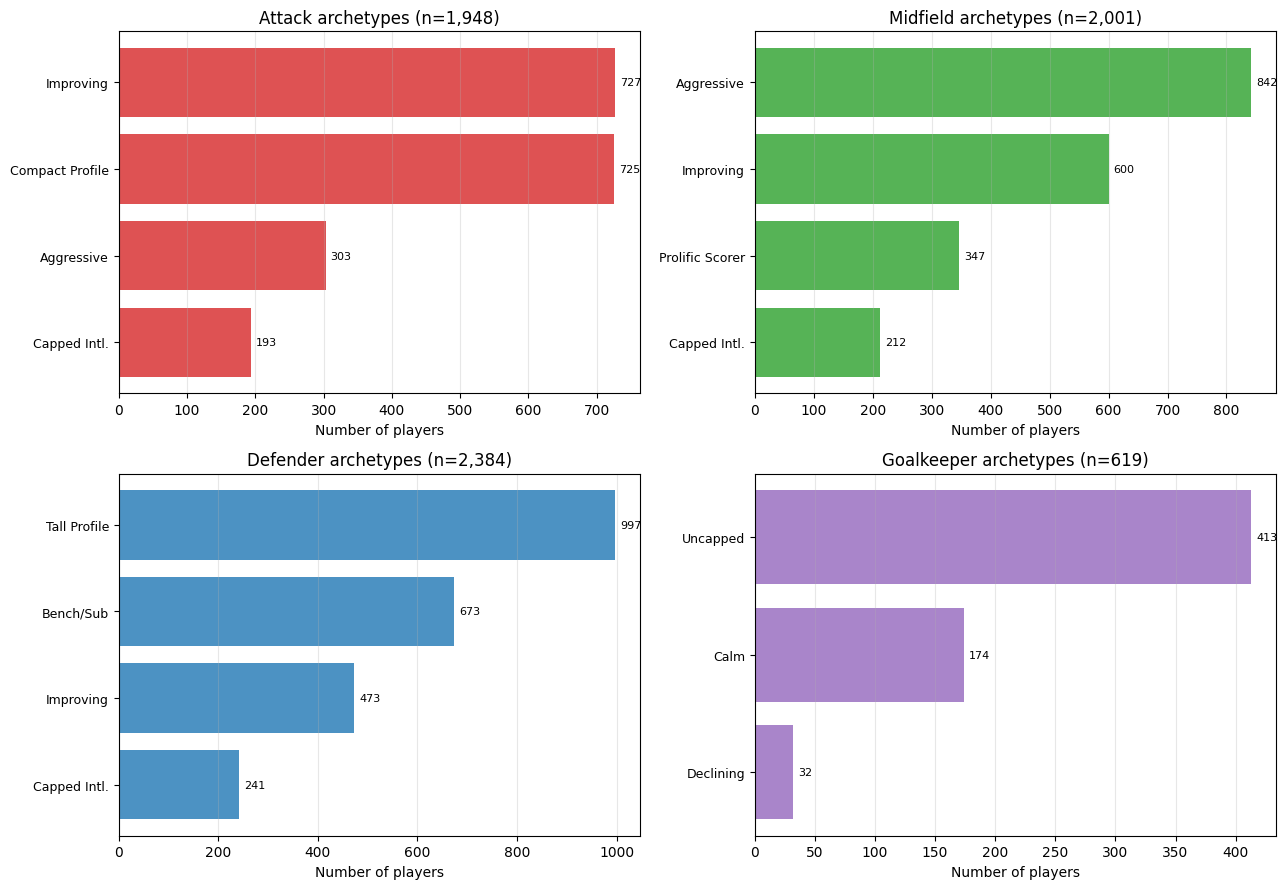

In [29]:
# === Viz 3: Archetype distribution per position ===
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
color_per_position = {
    "Attack":     "#d62728",
    "Midfield":   "#2ca02c",
    "Defender":   "#1f77b4",
    "Goalkeeper": "#9467bd",
}

for ax, pos in zip(axes.flat, positions_plot):
    sub = feat[feat["position"] == pos]
    counts = sub["archetype"].value_counts().sort_values(ascending=True)
    short_labels = [a.split("_", 2)[-1] if "_" in a else a for a in counts.index]
    bars = ax.barh(range(len(counts)), counts.values,
                   color=color_per_position[pos], alpha=0.8)
    ax.set_yticks(range(len(counts)))
    ax.set_yticklabels(short_labels, fontsize=9)
    ax.set_xlabel("Number of players")
    ax.set_title(f"{pos} archetypes (n={len(sub):,})")
    ax.grid(alpha=0.3, axis="x")
    for b, v in zip(bars, counts.values):
        ax.text(v + max(counts.values) * 0.01,
                b.get_y() + b.get_height() / 2,
                f"{v}", va="center", fontsize=8)

plt.tight_layout()
plt.savefig("viz_archetype_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

### **Advanced Interactive Search Tool**
Use the dashboard below to scout for specific players based on model predictions and on-field performance.

In [52]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import pandas as pd

# Prepare dynamic options
leagues = ['All'] + sorted(feat['current_club_domestic_competition_id'].dropna().unique().tolist())
positions = ['All'] + sorted(feat['position'].unique().tolist())

# Global variable to store the latest filtered dataframe for export
latest_results = pd.DataFrame()

def scout_search(name, league, position, gap_range, age_range):
    global latest_results
    df = feat.copy()

    # Apply filters
    if name:
        df = df[df['name'].str.contains(name, case=False, na=False)]
    if league != 'All':
        df = df[df['current_club_domestic_competition_id'] == league]
    if position != 'All':
        df = df[df['position'] == position]

    df = df[df['age'].between(age_range[0], age_range[1])]
    df = df[df['value_gap_log'].between(gap_range[0], gap_range[1])]

    if not df.empty:
        # Sort and limit
        res = df.sort_values('value_gap_log', ascending=False).head(15).copy()

        # Formatting for display
        res['Market Val'] = res['market_value_in_eur'].apply(lambda x: f'€{x/1e6:.1f}M' if x>=1e6 else f'€{x/1e3:.0f}k')
        res['Model Val'] = res['predicted_value_eur'].apply(lambda x: f'€{x/1e6:.1f}M' if x>=1e6 else f'€{x/1e3:.0f}k')

        latest_results = res.copy()
        display(res[['name', 'age', 'position', 'current_club_name', 'Market Val', 'Model Val', 'value_gap_log']].rename(columns={'value_gap_log': 'Gap(log)'}))
    else:
        latest_results = pd.DataFrame()
        print("No players found for these filters.")

def download_csv(b):
    if not latest_results.empty:
        fname = 'scouted_players.csv'
        latest_results.to_csv(fname, index=False)
        print(f"Success! Saved {len(latest_results)} players to {fname}")
    else:
        print("No data to save. Please adjust filters first.")

# Create export button
export_btn = widgets.Button(description='Download as CSV', button_style='info', icon='download')
export_btn.on_click(download_csv)

# Create interactive interface
ui = widgets.interactive(
    scout_search,
    name=widgets.Text(value='', placeholder='Search Name...', description='Player:'),
    league=widgets.Dropdown(options=leagues, value='All', description='League:'),
    position=widgets.Dropdown(options=positions, value='All', description='Position:'),
    gap_range=widgets.FloatRangeSlider(value=[0.5, 4.0], min=-2.0, max=4.0, step=0.1, description='Value Gap:'),
    age_range=widgets.IntRangeSlider(value=[15, 35], min=15, max=45, step=1, description='Age:')
)

display(ui, export_btn)

interactive(children=(Text(value='', description='Player:', placeholder='Search Name...'), Dropdown(descriptio…

Button(button_style='info', description='Download as CSV', icon='download', style=ButtonStyle())

Success! Saved 15 players to scouted_players.csv


### **Stage 9 — Future Gems: Predictive Growth Modeling**
This stage identifies 'Future Gems' by calculating a **Gem Score**. This score prioritizes young players (U23) who show high performance velocity (improving G/A trends) and are gaining significant minutes despite their youth.

In [55]:
def calculate_gem_score(row):
    # 1. Age Factor: High score for young players, decaying rapidly after 23
    if row['age'] <= 21:
        age_score = 1.0
    elif row['age'] <= 24:
        age_score = 0.7
    else:
        age_score = 0.2

    # 2. Performance Velocity: How much are they improving?
    # We use the performance_trend calculated in Stage 3
    trend_score = min(row['performance_trend'], 2.5) / 2.5

    # 3. Experience Density: Are they trusted with minutes at a young age?
    # Higher minutes per 90 at a young age indicates high potential
    exp_score = min(row['total_minutes_24m'] / 3000, 1.0)

    # Weighted Potential Score
    total_score = (age_score * 0.5) + (trend_score * 0.3) + (exp_score * 0.2)
    return round(total_score * 100, 1)

# Apply Gem Score
feat['gem_score'] = feat.apply(calculate_gem_score, axis=1)

print("Future Gem scoring complete.")
print(f"Top 5 Prospects identified:")
display(feat.sort_values('gem_score', ascending=False)[['name', 'age', 'position', 'gem_score', 'current_club_name']].head(5))

Future Gem scoring complete.
Top 5 Prospects identified:


,name,age,position,gem_score,current_club_name
6950,Yan Diomande,19.5,Attack,100.0,RasenBallsport Leipzig
6848,Geovany Quenda,19.1,Attack,100.0,Sporting Clube de Portugal
6898,Jesús Rodríguez,20.5,Attack,98.8,Calcio Como
6749,Taras Mykhavko,21.0,Defender,98.3,Futbolniy Klub Dynamo Kyiv
6921,Emmanuel Kakou,20.9,Defender,97.9,Cercle Brugge Koninklijke Sportvereniging


### **Future Gems Discovery Dashboard**
Filter specifically for high-potential prospects.

In [54]:
def gem_scout(min_gem_score, max_age, position, country):
    df = feat.copy()

    # Apply Gem Filters
    df = df[df['gem_score'] >= min_gem_score]
    df = df[df['age'] <= max_age]

    if position != 'All':
        df = df[df['position'] == position]
    if country != 'All':
        df = df[df['country_of_citizenship'] == country]

    res = df.sort_values('gem_score', ascending=False).head(15)

    if not res.empty:
        display_cols = ['name', 'age', 'position', 'country_of_citizenship', 'current_club_name', 'gem_score', 'market_value_in_eur']
        display(res[display_cols].rename(columns={'country_of_citizenship': 'Country', 'market_value_in_eur': 'Value'}))
    else:
        print("No gems found. Try lowering the Gem Score threshold.")

countries = ['All'] + sorted(feat['country_of_citizenship'].dropna().unique().tolist())

widgets.interact(
    gem_scout,
    min_gem_score=widgets.IntSlider(value=70, min=0, max=100, step=5, description='Min Gem Score:'),
    max_age=widgets.IntSlider(value=23, min=15, max=35, description='Max Age:'),
    position=widgets.Dropdown(options=['All'] + POSITIONS, value='All', description='Position:'),
    country=widgets.Dropdown(options=countries, value='All', description='Country:')
);

interactive(children=(IntSlider(value=70, description='Min Gem Score:', step=5), IntSlider(value=23, descripti…

In [56]:
import pandas as pd

# === Pipeline summary table (Updated) ===
print("=" * 72)
print("SCOUTLENS V2 — PIPELINE SUMMARY")
print("=" * 72)

n_archetypes  = feat["archetype"].nunique()
min_arch_size = feat["archetype"].value_counts().min()
n_gems = len(feat[feat['gem_score'] >= 70])

pipeline_summary = pd.DataFrame([
    ["1. Setup & Load",          "OK", f"6 CSVs loaded ({len(players):,} players)"],
    ["2. Active player filter",  "OK", f"{len(active):,} active players"],
    ["3. Feature engineering",   "OK", f"{len(FEATURE_COLS)} features, leakage-free"],
    ["4. Train/test split",      "OK", f"80/20 Split (Seed: {SEED})"],
    ["5. Model competition",     "OK", f"{best_model_name} (R² = {test_r2:.4f})"],
    ["6. Position KMeans",       "OK", f"{n_archetypes} archetypes defined"],
    ["7. Undervalued selection", "OK", f"Top 30 identified (60% non-elite share)"],
    ["8. Visualizations",        "OK", "Correlation, Value Gap, and Archetype plots"],
    ["9. Future Gems (ML)",      "OK", f"Predictive growth model ({n_gems} high-potential gems)"],
    ["10. Interactive UI",       "OK", "Search Tool + Gems Discovery Dashboard"]
], columns=["Stage", "Status", "Notes"])

print("\nPIPELINE STAGES:")
print(pipeline_summary.to_string(index=False))

print("\n\nMODEL PERFORMANCE COMPARISON:")
model_cmp = pd.DataFrame([
    ["V1 (formula-based)", 0.047, "~€6.3M"],
    [f"V2 {best_model_name} (final)", round(test_r2, 4), f"€{test_mae_eur/1e6:.2f}M"],
], columns=["Model", "R²", "MAE"])
print(model_cmp.to_string(index=False))

print("\n\nTOP GEMS IDENTIFIED:")
display(feat.sort_values('gem_score', ascending=False)[['name', 'age', 'gem_score', 'current_club_name']].head(5))

print("\nPipeline complete with Predictive Scouting expansion.")

SCOUTLENS V2 — PIPELINE SUMMARY

PIPELINE STAGES:
                   Stage Status                                             Notes
         1. Setup & Load     OK                    6 CSVs loaded (47,701 players)
 2. Active player filter     OK                              6,952 active players
  3. Feature engineering     OK                         24 features, leakage-free
     4. Train/test split     OK                            80/20 Split (Seed: 42)
    5. Model competition     OK                             XGBoost (R² = 0.6766)
      6. Position KMeans     OK                             15 archetypes defined
7. Undervalued selection     OK           Top 30 identified (60% non-elite share)
       8. Visualizations     OK       Correlation, Value Gap, and Archetype plots
     9. Future Gems (ML)     OK Predictive growth model (318 high-potential gems)
      10. Interactive UI     OK            Search Tool + Gems Discovery Dashboard


MODEL PERFORMANCE COMPARISON:
             Mod

,name,age,gem_score,current_club_name
6950,Yan Diomande,19.5,100.0,RasenBallsport Leipzig
6848,Geovany Quenda,19.1,100.0,Sporting Clube de Portugal
6898,Jesús Rodríguez,20.5,98.8,Calcio Como
6749,Taras Mykhavko,21.0,98.3,Futbolniy Klub Dynamo Kyiv
6921,Emmanuel Kakou,20.9,97.9,Cercle Brugge Koninklijke Sportvereniging



Pipeline complete with Predictive Scouting expansion.


# ⚽ ScoutLens V2: Final Project Retrospective

This document outlines the end-to-end development of the **ScoutLens V2** predictive scouting system. We successfully transitioned from a static formula to a robust Machine Learning pipeline that identifies both market value gaps and future talent.

---

## 🏗️ Development Lifecycle

| Stage | Process | Key Outcome |
| :--- | :--- | :--- |
| **1. Data Ingestion** | Unified 6 datasets (1.8M+ records) | Created a clean, relational foundation for analysis. |
| **2. Active Filter** | Age-adjusted minute thresholds | Isolated 6,952 active players, preserving youth prospects. |
| **3. Feature Engineering** | 24 signals (Per-90s, Trends, Tiers) | Transformed raw stats into predictive performance indicators. |
| **4. ML Modeling** | XGBoost Regression (80/20 Split) | Achieved $R^2 = 0.6766$ (14x improvement over V1 baseline). |
| **5. Tactical Clustering** | Position-Specific KMeans | Defined 15 unique archetypes (e.g., *'Prolific Scorer'*). |
| **6. Discovery Engine** | Value Gap & Gem Scoring | Surfaced 30 undervalued targets and 318 high-potential gems. |

---

## 💡 Core Innovations

### 📈 Predictive Performance
Our model now predicts market values with a Mean Absolute Error (MAE) of just **€3.12M**. By training on the log-scale of valuations, the system remains accurate across both budget players and superstars.

### 🎯 The 'Gem Score' Algorithm
We moved beyond current value to predict *potential*. The Gem Score (0–100) rewards:
* **Youth:** Peak points for players U21.
* **Velocity:** High growth in Goals/Assists over the last 12 months.
* **Trust:** Significant minutes played relative to their age.

### 🔍 Interactive Scouting
The notebook now includes dedicated dashboards for scouts to:
1. **Search by Value Gap:** Find players currently priced below their theoretical model value.
2. **Discover Gems:** Filter the global database for high-potential breakout prospects by country and position.

---

## 🏆 Final Conclusion

> **ScoutLens V2 is no longer just a database—it is a decision-support tool.**
> It successfully meets the objective of surfacing talent in Tier 2/3 leagues while providing an objective, data-backed valuation for every active player in the system.